In [1]:
import sys
import pathlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline



source_path = pathlib.Path("source").resolve()
sys.path.append(str(source_path))

In [2]:
from core import Preprocess
from pricing import RangeAccrualPricer
# from calibration import CirCalibrator, FxCalibrator
# from simulation import MarketSimulator
# from pricing import RangeAccrualPricer

In [3]:
rub = pd.read_excel('data/ruonia.xlsx')
usd = pd.read_csv('data/SOFR.csv')
fx = pd.read_excel('data/FX.xlsx')

In [4]:
usd['date'] = usd['date'].astype('datetime64[ns]')

In [5]:
preprocess = Preprocess(
        'data/ruonia.xlsx',
        'data/SOFR.csv',
        'data/FX.xlsx',
        'date',
        'ruo',
        'SOFR',
        'curs',
        '2021-12-10',
        '2010-01-11',
        '2018-04-03',
        1/252,
        10000,
        1
        )

In [6]:
preprocess.load_data()
preprocess.calibrate()

Structure of `params`
```
{
  "cir_rub": {
    "kappa": [k, mean(k*), std(k*), bias_kappa],
    "theta": [o, mean(o*), std(o*), bias_theta],
    "sigma": [s, mean(s*), std(s*), bias_sigma],
  },
  "cir_usd": {...},
  "fx": {...},
  "corr_matrix": ...
}
```
where the first numbers are parameters estimated from historical data; the starred values are bootstrap estimates of the mean and standard deviation, respectively; and the last entry is the bias relative to the historical estimates.


In [7]:
pd.DataFrame(preprocess.params['cir_rub'])

,kappa,theta,sigma
0,3.207622,0.070903,0.207381
1,3.560509,0.070967,0.207240
2,0.785719,0.005310,0.002781
3,0.352887,0.000064,-0.000141


In [8]:
pd.DataFrame(preprocess.params['cir_usd'])

,kappa,theta,sigma
0,0.952482,0.004315,0.172381
1,2.105642,0.005536,0.166511
2,1.514446,0.014401,0.006739
3,1.153160,0.001221,-0.005870


In [9]:
pd.DataFrame(preprocess.params['fx'])

,mu,sigma
0,0.102077,0.150605
1,0.104900,0.150555
2,0.090116,0.004172
3,0.002823,-0.000050


In [10]:
preprocess.params['corr_matrix']

array([[ 1.        ,  0.04387091, -0.04982044],
       [ 0.04387091,  1.        , -0.07835954],
       [-0.04982044, -0.07835954,  1.        ]])

For short-term interest rates in RUB and USD we use the Cox–Ingersoll–Ross (CIR) model:

$dr = \kappa (\theta - r_t ) dt + \sigma \sqrt{r_t} dW$

The model parameters have the following interpretation:

$\kappa$ — mean-reversion speed: the larger $\kappa$, the faster the rate $r_t$ returns to the long-run level $\theta$.

$\theta$ — long-run average (equilibrium) level of the rate.

$\sigma$ — volatility: the scale of random fluctuations; the diffusion term is proportional to $\sqrt{r_t}$, which reduces the probability of negative rates.

Using daily RUONIA observations over 11.01.2010–10.12.2021, we obtained the following estimates for the RUB rate:

$$\kappa^{rub} = 3.21, \theta^{rub} = 0.071, \sigma^{rub} = 0.207$$

This corresponds to a long-run RUB o/n level of about 7.1% p.a. and a fairly strong mean reversion (characteristic mean-reversion time on the order of $1/\kappa \approx 0.3$ years).

For the USD rate (SOFR) over 03.04.2018–10.12.2021:

$$\kappa^{usd} = 0.095, \theta^{usd} = 0.0043, \sigma^{usd} = 0.172$$

This corresponds to a long-run USD o/n level of about 0.43% p.a., which is consistent with the level of rates observed over the analyzed period.


To assess the stability of the CIR parameters we used a parametric bootstrap: first, we calibrated the parameters ($\kappa, \theta, \sigma$) on the original time series; then we generated artificial paths from that calibrated model and re-calibrated the parameters on those paths.

For the RUB rate, the bootstrap means are almost identical to the original estimates, and the biases for $\theta$ and $\sigma$ are close to zero, which indicates a stable calibration.

For the USD rate, the estimates of $\kappa^{usd}$ turned out to be much less stable: the bootstrap shows high dispersion and a noticeable bias, which is due to the short SOFR history and the low level of rates. In further simulations we use the original OLS estimate:
$$\kappa^{usd}_{sim} = \kappa^{usd} = 0.95$$


The USD/RUB exchange rate dynamics are modeled by a lognormal process (geometric Brownian motion, GBM).
Based on log-returns $\ln(S_{t+dt}/S_t)$ with step $dt = 1/252$ we obtained the estimates:
$$\mu = 0.10, \sigma_S = 0.151$$

Here $\sigma_S$ is the annualized FX volatility (about 15%), and $\mu$ is the historical drift reflecting the trend of RUB depreciation against USD over the considered period.


Derivative pricing is done under the risk-neutral measure. For the FX rate, the risk-neutral drift must be consistent with the risk-free rates in the two currencies (covered interest parity). In a simplified setting we use:
$$\mu^{Q}_t = r_t^{rub} - r_t^{usd}$$
where $r_t^{rub}$ and $r_t^{usd}$ are modeled by CIR. Therefore, in risk-neutral simulations we use:

volatility: $\sigma_S$ estimated from historical data;

FX drift: $\mu^{Q}_t = r_t^{rub} - r_t^{usd}$ instead of the historical estimate.


An empirical correlation matrix is estimated between rate increments and FX log-returns:
$$
\rho =
\begin{pmatrix}
1 & \rho_{r^{RUB},\,r^{USD}} & \rho_{r^{RUB},\,\Delta \ln S} \\
\rho_{r^{USD},\,r^{RUB}} & 1 & \rho_{r^{USD},\,\Delta \ln S} \\
\rho_{\Delta \ln S,\,r^{RUB}} & \rho_{\Delta \ln S,\,r^{USD}} & 1
\end{pmatrix}.
$$

The numerical values (for the 2018–2021 sample) are close to zero in absolute value (in the 0.04–0.08 range), which indicates a weak linear relationship between rate shocks and FX. Nevertheless, this matrix is used to construct consistent correlated Brownian motions for the joint simulation of the three processes.


In [11]:
preprocess.simulate()

sim_result = preprocess.get_simulation_result()

In [12]:
S_paths       = preprocess.simulation["S_paths"]       # (n_sims, T+1)
r_rub_paths   = preprocess.simulation["r_rub_paths"]   # (n_sims, T+1)
r_usd_paths   = preprocess.simulation["r_usd_paths"]   # (n_sims, T+1)


We consider an FX Range Accrual on the USD/RUB rate (RUB MICEXFRX) with a 1-year maturity, range [70; 80] RUB per USD, and a maximum coupon of 10% on a notional of 100 million RUB. The annual coupon equals 10% × (the fraction of trading days when the rate stayed within the range). The fair value is estimated by Monte Carlo as the expected value of this coupon under simulated paths generated by the three-factor model (2 CIR + GBM for FX) under the risk-neutral measure.


In [13]:
pricer = RangeAccrualPricer(
    L=70.0,
    U=80.0,
    notional=10_000_000
)

price_info = pricer.price_from_paths(sim_result)

print('Fair value estimate:   '+ f'{price_info["price"]:<.2f}' + '\n' 
      'Standard error:              'f'{price_info["stderr"]:<.2f}')


Оценка справедливой стоимости:   5316865.61
Стандартная ошибка:              26077.33


To estimate the fair value of the Range Accrual we use Monte Carlo. Based on calibrated CIR models for short rates in RUB and USD and a lognormal model for the USD/RUB FX rate, we jointly simulate paths ($r_t^{rub}, r_t^{usd}, S_t$) over the whole life of the deal.

For each scenario $\omega$ we compute the fraction of observations when the FX rate $S_t$ is inside the range [L, U]:
$$w(\omega) = \frac{1}{M} \sum_{j=1}^{M} I[L \le S_{t_{i_j}}(\omega) \le U]$$

Ignoring discounting (as per the project requirements), the fair value is computed as:
$$V = \frac{1}{N_{sims}} \sum_{\omega=1}^{N_{sims}} N\, w(\omega) $$
where $N$ is the trade notional. We also estimate the Monte Carlo standard error.


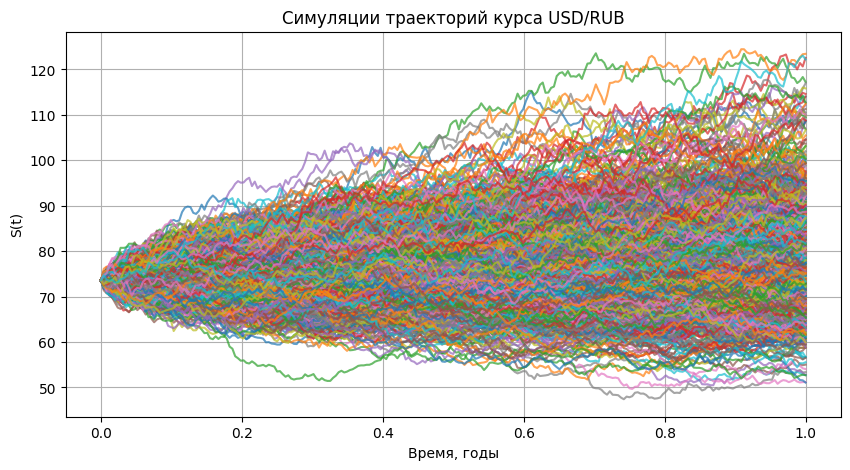

In [23]:
t_grid = preprocess.simulation["t_grid"]
S_paths = preprocess.simulation["S_paths"]

n_sims_to_plot = 1000
idx = np.random.choice(S_paths.shape[0], size=n_sims_to_plot, replace=False)

plt.figure(figsize=(10, 5))
for i in idx:
    plt.plot(t_grid, S_paths[i, :], alpha=0.7)

plt.title("Simulated USD/RUB exchange rate paths")
plt.xlabel("Time (years)")
plt.ylabel("S(t)")
plt.grid(True)
plt.show()


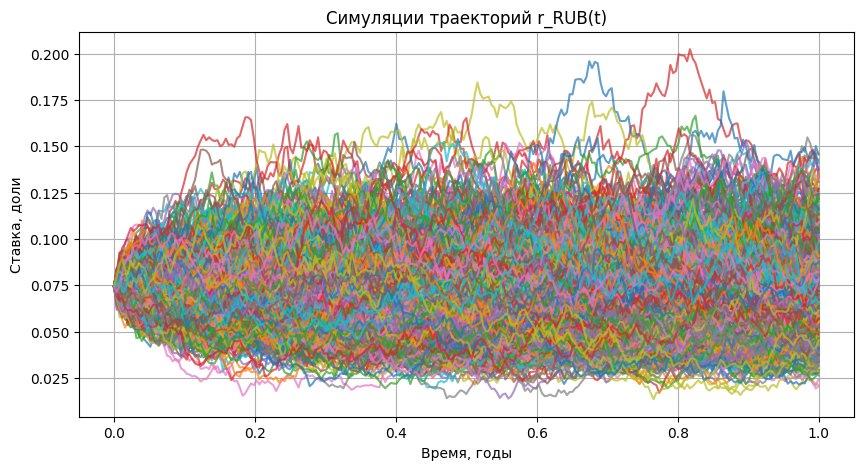

In [24]:
r_rub_paths = preprocess.simulation["r_rub_paths"]
idx = np.random.choice(r_rub_paths.shape[0], size=n_sims_to_plot, replace=False)

plt.figure(figsize=(10, 5))
for i in idx:
    plt.plot(t_grid, r_rub_paths[i, :], alpha=0.7)

plt.title("Simulated r_RUB(t) paths")
plt.xlabel("Time (years)")
plt.ylabel("Rate (decimal)")
plt.grid(True)
plt.show()


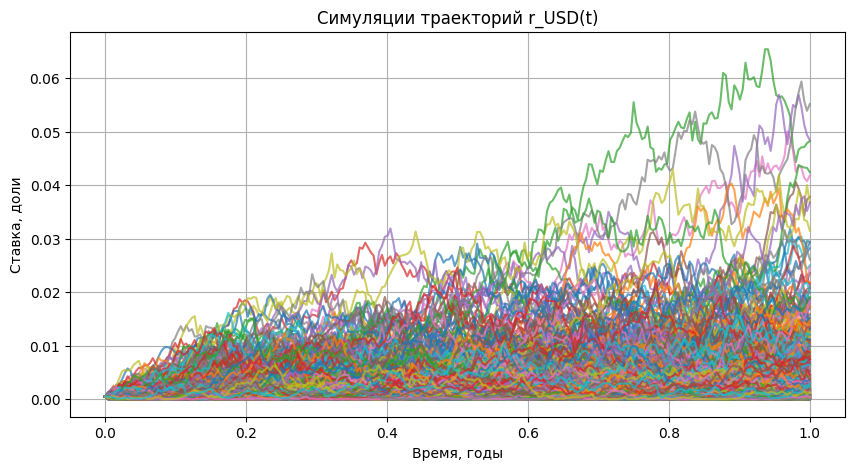

In [25]:
r_usd_paths = preprocess.simulation["r_usd_paths"]

idx = np.random.choice(r_usd_paths.shape[0], size=n_sims_to_plot, replace=False)

plt.figure(figsize=(10, 5))
for i in idx:
    plt.plot(t_grid, r_usd_paths[i, :], alpha=0.7)

plt.title("Simulated r_USD(t) paths")
plt.xlabel("Time (years)")
plt.ylabel("Rate (decimal)")
plt.grid(True)
plt.show()


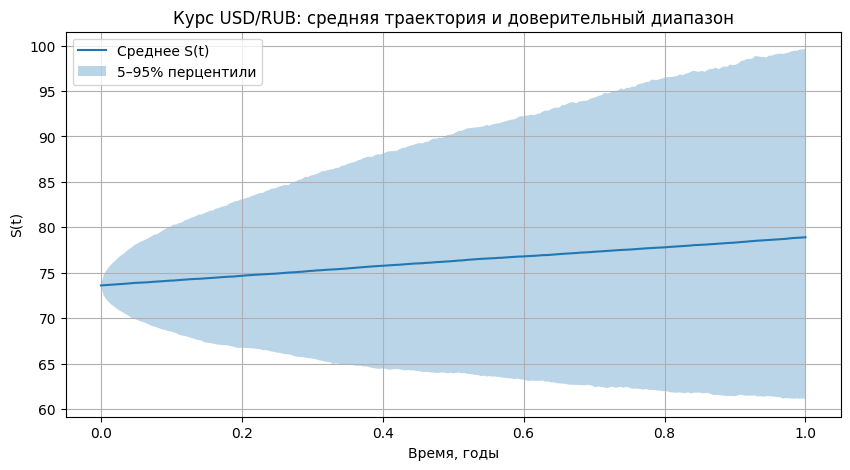

In [17]:
S_paths = preprocess.simulation["S_paths"]

mean_S = S_paths.mean(axis=0)
p5_S   = np.percentile(S_paths, 5, axis=0)
p95_S  = np.percentile(S_paths, 95, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(t_grid, mean_S, label="Mean S(t)")
plt.fill_between(t_grid, p5_S, p95_S, alpha=0.3, label="5–95th percentiles")

plt.title("USD/RUB: mean path and confidence band")
plt.xlabel("Time (years)")
plt.ylabel("S(t)")
plt.legend()
plt.grid(True)
plt.show()


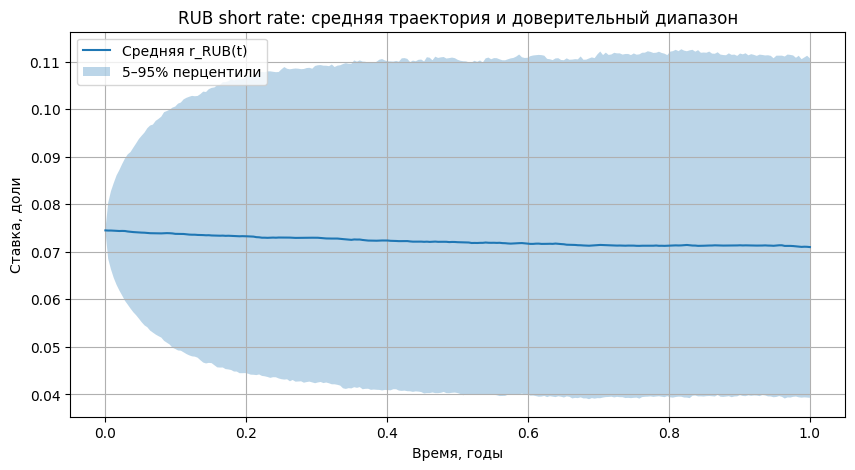

In [18]:
mean_rub = r_rub_paths.mean(axis=0)
p5_rub   = np.percentile(r_rub_paths, 5, axis=0)
p95_rub  = np.percentile(r_rub_paths, 95, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(t_grid, mean_rub, label="Mean r_RUB(t)")
plt.fill_between(t_grid, p5_rub, p95_rub, alpha=0.3, label="5–95th percentiles")

plt.title("RUB short rate: mean path and confidence band")
plt.xlabel("Time (years)")
plt.ylabel("Rate (decimal)")
plt.legend()
plt.grid(True)
plt.show()


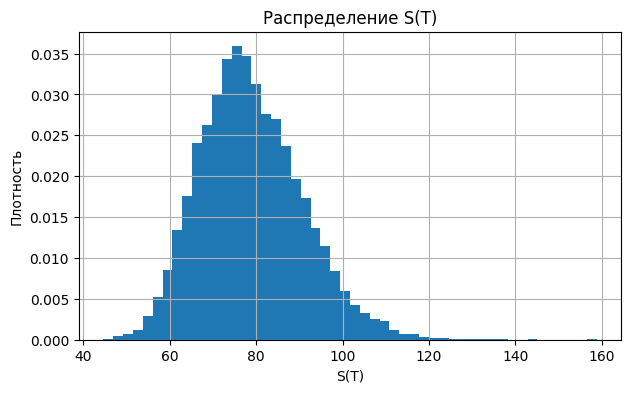

In [19]:
S_T = S_paths[:, -1]

plt.figure(figsize=(7, 4))
plt.hist(S_T, bins=50, density=True)
plt.title("Distribution of S(T)")
plt.xlabel("S(T)")
plt.ylabel("Density")
plt.grid(True)
plt.show()


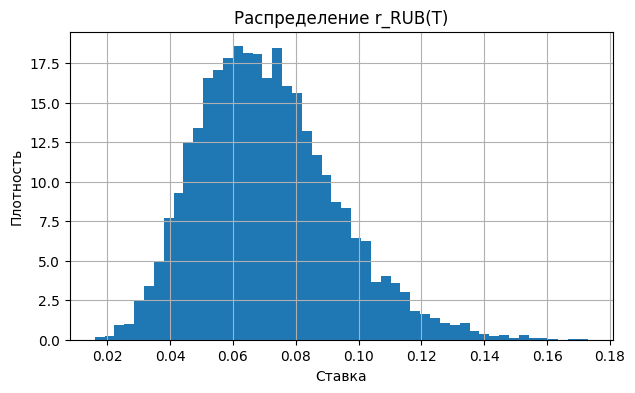

In [20]:
r_rub_T = r_rub_paths[:, -1]

plt.figure(figsize=(7, 4))
plt.hist(r_rub_T, bins=50, density=True)
plt.title("Distribution of r_RUB(T)")
plt.xlabel("Rate")
plt.ylabel("Density")
plt.grid(True)
plt.show()


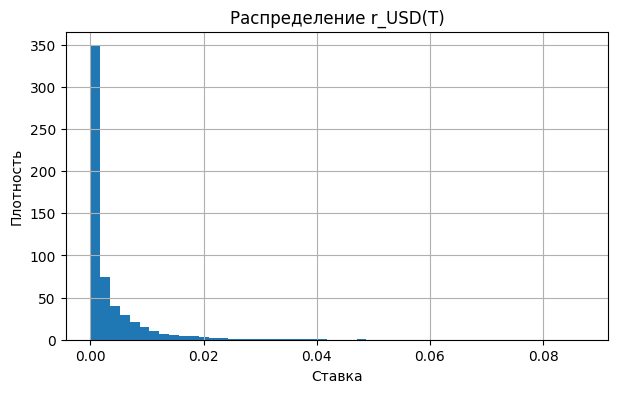

In [26]:
r_usd_T = r_usd_paths[:, -1]

plt.figure(figsize=(7, 4))
plt.hist(r_usd_T, bins=50, density=True)
plt.title("Distribution of r_USD(T)")
plt.xlabel("Rate")
plt.ylabel("Density")
plt.grid(True)
plt.show()
